###1. Verifikasi GPU

In [ ]:
# Memeriksa ketersediaan GPU NVIDIA di Colab
import torch
print("CUDA tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "GPU belum aktif! Runtime > Change runtime type > A100 / T4 GPU, lalu jalankan ulang dari sel 1."
print(torch.cuda.get_device_name(0))


CUDA tersedia: True
NVIDIA A100-SXM4-40GB


###2. Menghubungkan ke Google Drive

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')

DRIVE_ROOT = '/content/drive/MyDrive/DIVINA_ORAGEN'
print("Folder Drive ditemukan:", os.path.exists(DRIVE_ROOT))
print("ORAGEN.zip ada:", os.path.exists(f'{DRIVE_ROOT}/ORAGEN.zip'))
print("DIVINA.zip ada:", os.path.exists(f'{DRIVE_ROOT}/DIVINA.zip') or os.path.exists(f'{DRIVE_ROOT}/DIVINA/DIVINA.zip'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder Drive ditemukan: True
ORAGEN.zip ada: True


###3. Ambil kode ORAGEN (GitHub) & ekstrak dataset

In [ ]:
import os, glob, subprocess

# --- 1. Ambil kode ORAGEN terbaru dari GitHub ---
!rm -rf /content/ORAGEN
!git clone https://github.com/Brata24/oragen-divina.git /content/ORAGEN

# --- 2. Ekstrak dataset BRAVE-MASKS (ORAGEN.zip) ---
!rm -rf /content/dataset && mkdir -p /content/dataset
assert os.path.exists(f'{DRIVE_ROOT}/ORAGEN.zip'), "ORAGEN.zip tidak ada di Drive/DIVINA_ORAGEN"
!unzip -q {DRIVE_ROOT}/ORAGEN.zip -d /content/dataset/

data_root = None
for root, dirs, files in os.walk('/content/dataset'):
    if 'audio' in dirs and 'video' in dirs and 'divina' not in root:
        data_root = root
        break
assert data_root, "Folder audio/video tidak ditemukan di dalam ORAGEN.zip"
if data_root != '/content/dataset/shared':
    if os.path.exists('/content/dataset/shared'):
        !rm -rf /content/dataset/shared
    os.symlink(data_root, '/content/dataset/shared')
print("Dataset BRAVE-MASKS root:", data_root, "-> /content/dataset/shared")

# --- 3. Ekstrak dataset DIVINA (DIVINA.zip) ---
divina_zip = f'{DRIVE_ROOT}/DIVINA.zip' if os.path.exists(f'{DRIVE_ROOT}/DIVINA.zip') else (
    f'{DRIVE_ROOT}/DIVINA/DIVINA.zip' if os.path.exists(f'{DRIVE_ROOT}/DIVINA/DIVINA.zip') else None
)
if divina_zip:
    !rm -rf /content/dataset/divina && mkdir -p /content/dataset/divina
    !unzip -q -o "{divina_zip}" -d /content/dataset/divina/
    print("Dataset DIVINA berhasil diekstrak dari:", divina_zip, "-> /content/dataset/divina")
elif os.path.exists(f'{DRIVE_ROOT}/DIVINA/audio') and os.path.exists(f'{DRIVE_ROOT}/DIVINA/video'):
    if os.path.exists('/content/dataset/divina'):
        !rm -rf /content/dataset/divina
    os.symlink(f'{DRIVE_ROOT}/DIVINA', '/content/dataset/divina')
    print("Dataset DIVINA dihubungkan dari folder Drive/DIVINA -> /content/dataset/divina")
else:
    print("PERINGATAN: DIVINA.zip belum ditemukan di Drive/DIVINA_ORAGEN! Pastikan sudah upload C:\\TA2\\Dataset\\DIVINA.zip ke Google Drive.")

# --- 4. Label & VAD metadata ---
os.makedirs('/content/ORAGEN/data', exist_ok=True)
for fn in ['bravemasks_labels.csv', 'bravemasks_vad.pickle', 'divina_labels.csv', 'divina_vad.pickle']:
    dst = f'/content/ORAGEN/data/{fn}'
    if not os.path.exists(dst) and os.path.exists(f'{DRIVE_ROOT}/{fn}'):
        !cp {DRIVE_ROOT}/{fn} {dst}
    print(fn, "ada:", os.path.exists(dst))


Cloning into '/content/ORAGEN'...
remote: Enumerating objects: 119, done.
remote: Counting objects: 100% (119/119), done.
remote: Compressing objects: 100% (69/69), done.
remote: Total 119 (delta 41), reused 117 (delta 39), pack-reused 0 (from 0)
Receiving objects: 100% (119/119), 65.51 KiB | 2.98 MiB/s, done.
Resolving deltas: 100% (41/41), done.
Dataset root: /content/dataset/shared -> /content/dataset/shared
bravemasks_labels.csv ada: True
bravemasks_vad.pickle ada: True


In [ ]:
# Memeriksa isi folder DIVINA_ORAGEN di Google Drive untuk melihat daftar file yang ada
import os

drive_path = '/content/drive/MyDrive/DIVINA_ORAGEN'
if os.path.exists(drive_path):
    print(f"Isi folder {drive_path}:")
    files = os.listdir(drive_path)
    if files:
        for f in files:
            print(f" - {f}")
    else:
        print("Folder kosong!")
else:
    print(f"Folder {drive_path} tidak ditemukan di Drive Anda.")

Isi folder /content/drive/MyDrive/DIVINA_ORAGEN:
 - DIVINA
 - bravemasks_labels.csv
 - bravemasks_vad.pickle
 - ORAGEN.zip
 - features
 - logs


###4. Install library

In [ ]:
!pip install -q librosa soundfile soxr tensorboard

###5. Patch kompatibilitas `transformers` versi baru


In [ ]:
import re, os

def patch_file(path, class_names):
    with open(path, 'r') as f:
        src = f.read()
    # buang atribut lama (versi list) bila ada
    src = re.sub(r"\n[ ]+_tied_weights_keys = \[\]\n[ ]+all_tied_weights_keys = (\[\]|\{\})\n", "\n", src)
    for cls in class_names:
        header = re.search(rf"class {cls}\(.*?\):\n", src)
        if header:
            src = src[:header.end()] + "    _tied_weights_keys = []\n    all_tied_weights_keys = {}\n\n" + src[header.end():]
    with open(path, 'w') as f:
        f.write(src)
    print("Patched:", path, class_names)

base = '/content/ORAGEN/src'
patch_file(f'{base}/audio/models/audio_models.py', ['AGenderAudioW2V2Model', 'AGenderAudioHuBERTModel'])
patch_file(f'{base}/fusion/models/models_wrappers.py', ['AudioWrapperModel'])

Patched: /content/ORAGEN/src/audio/models/audio_models.py ['AGenderAudioW2V2Model', 'AGenderAudioHuBERTModel']
Patched: /content/ORAGEN/src/fusion/models/models_wrappers.py ['AudioWrapperModel']


###6. Konfigurasi default_config.py (Skenario A & B, 10 Kelas Oklusi Termasuk DIVINA)
Menulis konfigurasi dataset BRAVE-MASKS dan DIVINA secara lengkap dengan 10 kelas oklusi.

In [ ]:
import os

config_dir = '/content/ORAGEN/src/configs'
os.makedirs(config_dir, exist_ok=True)

config_code = """import sys
sys.path.append('/content/ORAGEN/src')

BRAVEMASKS_RAW = '/content/dataset/shared'
DIVINA_RAW     = '/content/dataset/divina'

data_config = {
    'BRAVEMASKS': {
        'RAW_DATA_ROOT': BRAVEMASKS_RAW,
        'PROCESSED_DATA_ROOT': BRAVEMASKS_RAW,
        'VAD_FILE_PATH': '/content/ORAGEN/data/bravemasks_vad.pickle',
        'LABELS_FILE_PATH': '/content/ORAGEN/data/bravemasks_labels.csv',
        'C_NAMES': {
            'gen': ['female', 'male'],
            'mask': ['No mask', 'Tissue mask', 'Medical mask', 'Protective mask (ffp2/ffp3)',
                     'Respirator', 'Protective face shield', 'Hijab', 'Helmet', 'Glasses', 'Hat'],
        },
    },
    'DIVINA': {
        'RAW_DATA_ROOT': DIVINA_RAW,
        'PROCESSED_DATA_ROOT': DIVINA_RAW,
        'VAD_FILE_PATH': '/content/ORAGEN/data/divina_vad.pickle',
        'LABELS_FILE_PATH': '/content/ORAGEN/data/divina_labels.csv',
        'C_NAMES': {
            'gen': ['female', 'male'],
            'mask': ['No mask', 'Tissue mask', 'Medical mask', 'Protective mask (ffp2/ffp3)',
                     'Respirator', 'Protective face shield', 'Hijab', 'Helmet', 'Glasses', 'Hat'],
        },
    },
}

training_config = {
    'LOGS_ROOT': '/content/drive/MyDrive/DIVINA_ORAGEN/logs',
    'MODEL': {'cls': None, 'args': {}},
    'FEATURE_EXTRACTOR': {
        'FEATURES_ROOT': '/content/drive/MyDrive/DIVINA_ORAGEN/features',
        'FEATURES_FILE_NAME': 'SAMPLES',
        'WIN_MAX_LENGTH': 4,
        'WIN_SHIFT': 2,
        'WIN_MIN_LENGTH': 1,
        'SR': 16000,
    },
    'NUM_EPOCHS': 500,
    'BATCH_SIZE': 16,
    'EARLY_STOPPING': {'patience': 20, 'min_delta': 0.05},
    'OPTIMIZER': {'cls': 'AdamW', 'lr': 1e-4},
    'SCHEDULER': {'cls': 'CosineAnnealingWarmRestarts', 'T_0': 10, 'T_mult': 2},
    'AUGMENTATION': True,
    'USE_AMP': True,
}
"""

with open(f'{config_dir}/default_config.py', 'w') as f:
    f.write(config_code)
for alias in ['multimodal_bm_config.py', 'unimodal_bm_config.py', 'unimodal_config.py', 'multimodal_config.py']:
    with open(f'{config_dir}/{alias}', 'w') as f:
        f.write("from configs.default_config import data_config, training_config\n")
print("Konfigurasi Skenario A & B (10 kelas oklusi) berhasil ditulis.")


In [ ]:
import os, pandas as pd

checks = {
    'run_train': '/content/ORAGEN/src/fusion/run_train_multimodal_maskagender.py',
    'labels': '/content/ORAGEN/data/bravemasks_labels.csv',
    'vad': '/content/ORAGEN/data/bravemasks_vad.pickle',
    'audio dir': '/content/dataset/shared/audio',
    'video dir': '/content/dataset/shared/video',
}
for k, v in checks.items():
    print(f"{k:10s}", "OK " if os.path.exists(v) else "HILANG", v)

df = pd.read_csv('/content/ORAGEN/data/bravemasks_labels.csv', low_memory=False)
row = df.iloc[0]
print("Contoh audio ada:", os.path.exists('/content/dataset/shared/' + row['audio_file_path']))
print("Contoh gambar ada:", os.path.exists('/content/dataset/shared/' + row['image_file_path']))
print(df['subset'].value_counts())

run_train  OK  /content/ORAGEN/src/fusion/run_train_multimodal_maskagender.py
labels     OK  /content/ORAGEN/data/bravemasks_labels.csv
vad        OK  /content/ORAGEN/data/bravemasks_vad.pickle
audio dir  OK  /content/dataset/shared/audio
video dir  OK  /content/dataset/shared/video
Contoh audio ada: True
Contoh gambar ada: True
subset
train         113349
test           61521
blind_test     50790
Name: count, dtype: int64


In [ ]:
import os

dataset_file = '/content/ORAGEN/src/fusion/data/agender_multimodal_features_dataset.py'
assert os.path.exists(dataset_file), 'ORAGEN belum ada. Jalankan ulang dari sel clone/ekstrak dataset (sel 5) sampai sel config, baru sel ini.'

code = open(dataset_file, 'r', encoding='utf-8').read().replace('\r\n', '\n').replace('self.full_features_path, \n', 'self.full_features_path,\n')

# Lewati file audio yang tidak ada di disk
old1 = """            sample_fp = os.path.join(self.data_root, sample_filename)
"""
new1 = old1 + """            if not os.path.exists(sample_fp):
                continue
"""
if 'if not os.path.exists(sample_fp):' not in code:
    assert old1 in code, 'Target patch 1 tidak ditemukan'
    code = code.replace(old1, new1, 1)

# Resume cache: jangan ekstrak ulang fitur yang sudah ada
old2 = """                features = {'acoustic_features': audio_feature_extractor(wave), 'visual_features': video_feature_extractor(images_fp)}
"""
new2 = """                feature_target_path = os.path.join(self.full_features_path, sample_filename.replace('.wav', '_{0}.dat'.format(w_idx)))
                features = None
                if not os.path.exists(feature_target_path):
                    features = {'acoustic_features': audio_feature_extractor(wave), 'visual_features': video_feature_extractor(images_fp)}
"""
old3 = """                save_data(features, os.path.join(self.full_features_path,
                                                 sample_filename.replace('.wav', '_{0}.dat'.format(w_idx))))"""
new3 = """                if features is not None:
                    save_data(features, feature_target_path)"""
if 'feature_target_path' not in code:
    assert old2 in code and old3 in code, 'Target patch 2 tidak ditemukan'
    code = code.replace(old2, new2, 1).replace(old3, new3, 1)

open(dataset_file, 'w', encoding='utf-8').write(code)
import py_compile; py_compile.compile(dataset_file, doraise=True)
print('Patch OK (skip file hilang + resume cache)')


Patch OK (skip file hilang + resume cache)


###9. [SUDAH SELESAI - LEWATI SEL INI] Jalankan Training Skenario A (Baseline BRAVE-MASKS)
> **Catatan:** Training Model A sudah selesai (berhenti di Epoch 23 dengan Epoch Terbaik = **Epoch 3**, `age_MAE = 8.308 tahun`). Checkpoint `epoch_3.pth` sudah tersimpan di Google Drive. **Jangan jalankan ulang sel ini**, langsung lompat ke **Bagian 11** di bawah!

In [ ]:
# [SUDAH SELESAI] Jangan di-run ulang jika epoch_3.pth Skenario A sudah ada di Drive
%cd /content/ORAGEN
!python src/fusion/run_train_multimodal_maskagender.py --scenario A


Patch OK -> NUM_EPOCHS & EARLY_STOPPING diambil dari config (sel konfigurasi)


###10. Visualisasi hasil training (kurva loss/metrik, confusion matrix, distribusi data)

Eksperimen: w-AugmentationMultiModalMaskAgenderInter-ScenarioA-6cls-2-MaskAgenderAVModelV3-2026.11.22-08.47.36


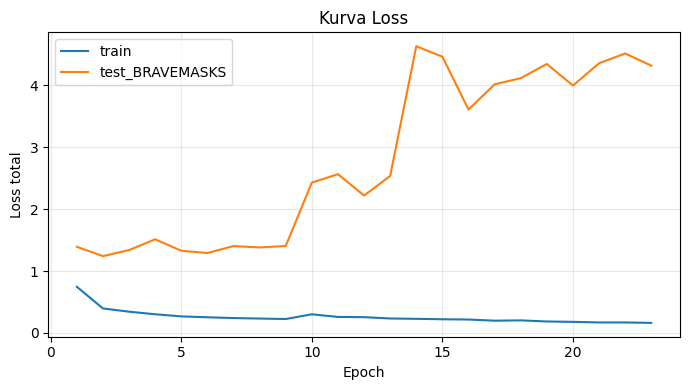

Epoch terbaik (MAE evaluasi minimum): 3


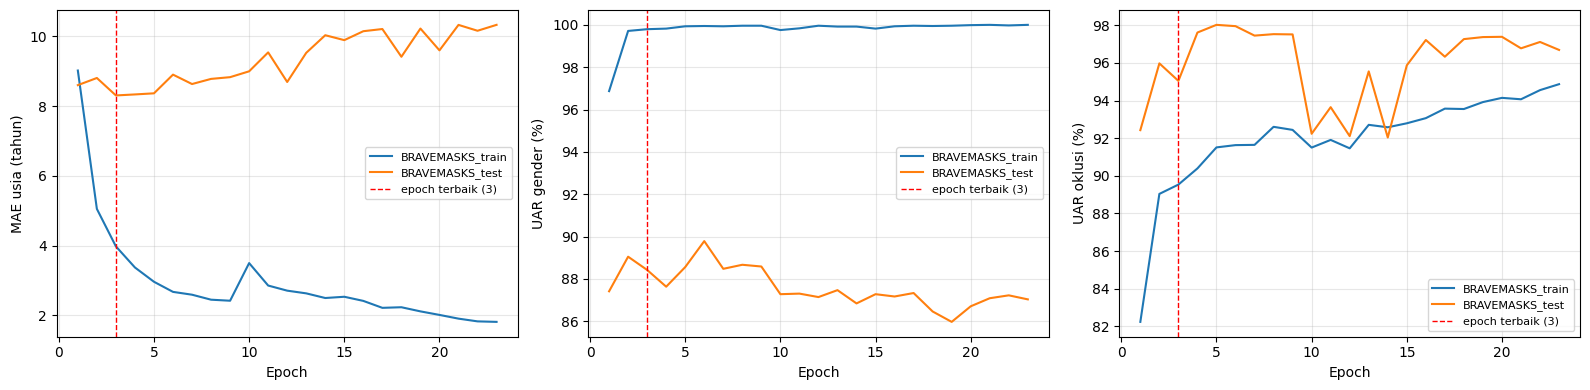

,epoch_3
epoch,3.000000
train_loss,0.343617
BRAVEMASKS_train_age_MAE,3.980064
BRAVEMASKS_train_gen_UAR,99.794925
BRAVEMASKS_train_gen_MacroF1,99.794914
BRAVEMASKS_train_gen_Precision,99.794906
BRAVEMASKS_train_mask_UAR,89.532715
test_BRAVEMASKS_loss,1.339119
BRAVEMASKS_test_age_MAE,8.308174
BRAVEMASKS_test_gen_UAR,88.419619


epoch_3_BRAVEMASKS_gen_test_BRAVEMASKS_8.308.svg


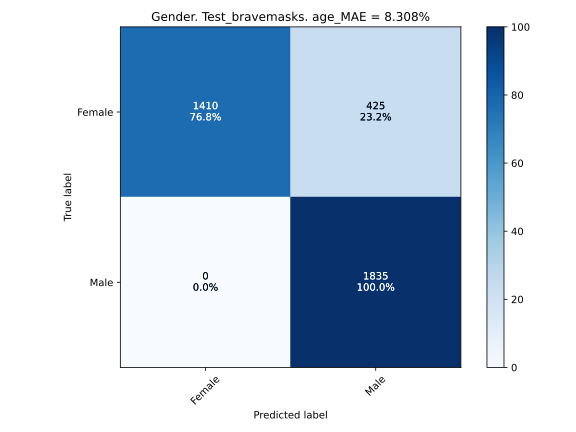

epoch_3_BRAVEMASKS_mask_test_BRAVEMASKS_8.308.svg


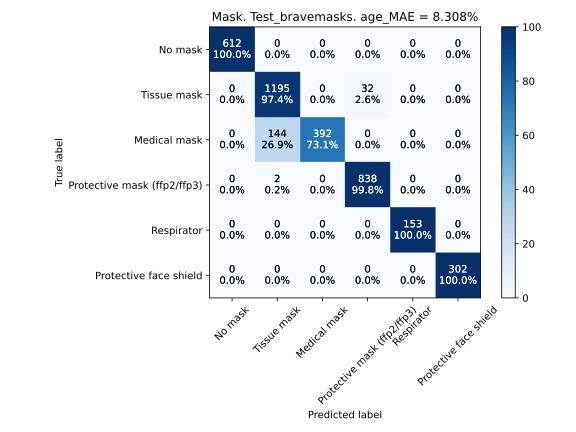

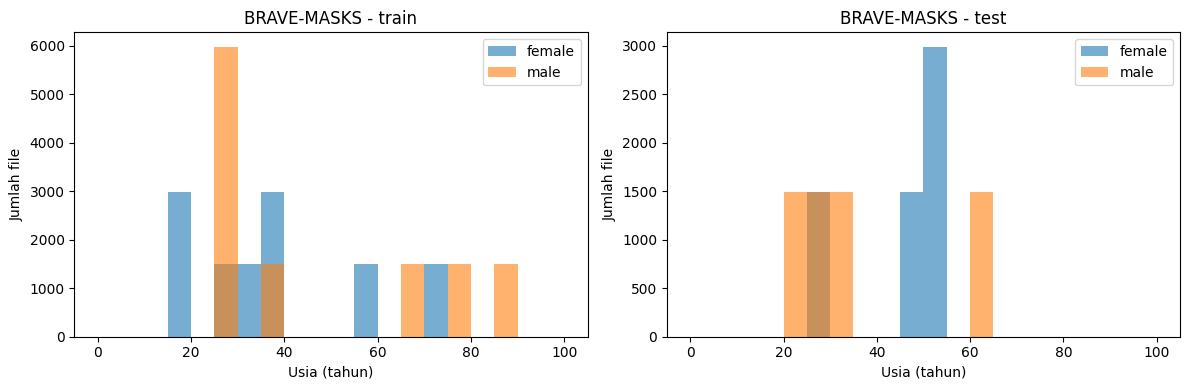

Semua gambar tersimpan di: /content/drive/MyDrive/DIVINA_ORAGEN/figures


In [ ]:
# ==== VISUALISASI HASIL TRAINING (untuk Bab 4 TA) ====
import os, glob, shutil
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display

LOGS = '/content/drive/MyDrive/DIVINA_ORAGEN/logs'
FIG  = '/content/drive/MyDrive/DIVINA_ORAGEN/figures'
os.makedirs(FIG, exist_ok=True)

# Ambil eksperimen terbaru (atau isi manual: EXP = f'{LOGS}/<nama_folder>')
exps = sorted([d for d in glob.glob(f'{LOGS}/*') if os.path.exists(f'{d}/logs/stats.csv')], key=os.path.getmtime)
assert exps, 'Belum ada hasil training di folder logs'
EXP = exps[-1]
NAME = os.path.basename(EXP)
print('Eksperimen:', NAME)

df = pd.read_csv(f'{EXP}/logs/stats.csv', sep=';')

# ---------- 1) Learning curve: loss train vs evaluasi ----------
loss_cols = [c for c in df.columns if c.endswith('_loss')]
plt.figure(figsize=(7, 4))
for c in loss_cols:
    plt.plot(df['epoch'], df[c], label=c.replace('_loss', ''))
plt.xlabel('Epoch'); plt.ylabel('Loss total'); plt.title('Kurva Loss'); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/{NAME}_loss.png', dpi=300); plt.show()

# ---------- 2) Kurva metrik per epoch + epoch terbaik ----------
eval_mae = [c for c in df.columns if c.endswith('age_MAE') and '_train_' not in c]
best_epoch = int(df.loc[df[eval_mae].mean(axis=1).idxmin(), 'epoch']) if eval_mae else None
print('Epoch terbaik (MAE evaluasi minimum):', best_epoch)

metrics = [('age_MAE', 'MAE usia (tahun)'), ('gen_UAR', 'UAR gender (%)'), ('mask_UAR', 'UAR oklusi (%)')]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (m, lbl) in zip(axes, metrics):
    for c in [c for c in df.columns if c.endswith(m)]:
        ax.plot(df['epoch'], df[c], label=c.replace('_' + m, ''))
    if best_epoch:
        ax.axvline(best_epoch, color='red', ls='--', lw=1, label=f'epoch terbaik ({best_epoch})')
    ax.set_xlabel('Epoch'); ax.set_ylabel(lbl); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/{NAME}_metrics.png', dpi=300); plt.show()

# ---------- 3) Ringkasan metrik pada epoch terbaik ----------
if best_epoch:
    row = df[df['epoch'] == best_epoch].T
    row.columns = [f'epoch_{best_epoch}']
    display(row)
    row.to_csv(f'{FIG}/{NAME}_best_epoch_metrics.csv')

# ---------- 4) Confusion matrix (gender & oklusi) pada epoch terbaik ----------
cms = sorted(glob.glob(f'{EXP}/models/**/epoch_{best_epoch}_*.svg', recursive=True)) if best_epoch else []
seen = set()
for fp in cms:
    key = '_'.join(os.path.basename(fp).split('_')[:-1])  # 1 file per task/fase
    if key in seen:
        continue
    seen.add(key)
    shutil.copy(fp, FIG)
    print(os.path.basename(fp)); display(SVG(fp))

# ---------- 5) Distribusi usia & gender dataset (seperti Fig. 6 artikel ORAGEN) ----------
lab = pd.read_csv('/content/ORAGEN/data/bravemasks_labels.csv', low_memory=False).drop_duplicates('audio_file_path')
subsets = [s for s in ['train', 'test'] if s in lab['subset'].unique()]
fig, axes = plt.subplots(1, len(subsets), figsize=(6 * len(subsets), 4), squeeze=False)
for ax, sub in zip(axes[0], subsets):
    d = lab[lab['subset'] == sub]
    for g in sorted(d['gender'].dropna().astype(str).unique()):
        ages = pd.to_numeric(d[d['gender'].astype(str) == g]['age'], errors='coerce').dropna()
        ax.hist(ages, bins=range(0, 101, 5), alpha=.6, label=g)
    ax.set_title(f'BRAVE-MASKS - {sub}'); ax.set_xlabel('Usia (tahun)'); ax.set_ylabel('Jumlah file'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/bravemasks_age_gender_distribution.png', dpi=300); plt.show()

print('Semua gambar tersimpan di:', FIG)


###11. Evaluasi Model Baseline (Skenario A) pada Test DIVINA & Test BRAVE-MASKS
Sesuai Proposal Bab 3.8.1 & 3.8.3: Menguji checkpoint terbaik Model A (`epoch_3.pth`) pada subset **Test DIVINA (Indonesia)** dan **Test BRAVE-MASKS**, lengkap dengan analisis per jenis oklusi (`NO, HJ, HM, KA, TP`) dan kontribusi modalitas (`Audio-Visual`, `Audio-Only`, `Visual-Only`).

In [ ]:
# ==== EVALUASI ZERO-SHOT MODEL BASELINE (SKENARIO A) PADA TEST DIVINA ====
%cd /content/ORAGEN
!python src/fusion/run_eval_zeroshot_divina.py --scenario A --subset test


###12. Jalankan Training Skenario B (Model Diperluas: BRAVE-MASKS + DIVINA Train, 10 Kelas Oklusi)
Melatih ulang blok MTCMA ORAGEN menggunakan gabungan data latihan internasional (`BRAVE-MASKS`) + data latihan lokal Indonesia (`DIVINA` hasil augmentasi Opsi B) dengan 10 kelas oklusi, 500 epoch, dan Early Stopping (`patience=20`).

In [ ]:
# ==== JALANKAN TRAINING SKENARIO B (BRAVE-MASKS + DIVINA) ====
%cd /content/ORAGEN
!python src/fusion/run_train_multimodal_maskagender.py --scenario B


###13. Evaluasi Lengkap Skenario B & Tabel Perbandingan Skenario A vs Skenario B (Domain Shift)
Mengevaluasi checkpoint terbaik Skenario B pada **Test DIVINA** (per jenis oklusi & per modalitas) sekaligus mencetak **Tabel Utama Bab 4: Selisih Performa (Delta Domain Shift yang Teratasi)** antara Skenario A dan Skenario B.

In [ ]:
# ==== EVALUASI SKENARIO B & TABEL PERBANDINGAN SKENARIO A VS B ====
%cd /content/ORAGEN
!python src/fusion/run_eval_zeroshot_divina.py --scenario B --subset test
!python src/fusion/run_eval_zeroshot_divina.py --compare --subset test


###14. Visualisasi Hasil Training Skenario B & Distribusi Dataset DIVINA (untuk Bab 4 TA)
Menghasilkan grafik Kurva Loss, Kurva Metrik per Epoch, Confusion Matrix 10 Kelas Oklusi, dan Histogram Distribusi Usia/Gender DIVINA.

In [ ]:
# ==== VISUALISASI HASIL TRAINING SKENARIO B & DISTRIBUSI DIVINA ====
import os, glob, shutil
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, Image, display

LOGS = '/content/drive/MyDrive/DIVINA_ORAGEN/logs'
FIG  = '/content/drive/MyDrive/DIVINA_ORAGEN/figures'
os.makedirs(FIG, exist_ok=True)

exps = sorted([d for d in glob.glob(f'{LOGS}/*ScenarioB*') if os.path.exists(f'{d}/logs/stats.csv')], key=os.path.getmtime)
assert exps, 'Belum ada hasil training Skenario B di folder logs'
EXP = exps[-1]
NAME = os.path.basename(EXP)
print('Eksperimen Skenario B:', NAME)

df = pd.read_csv(f'{EXP}/logs/stats.csv', sep=';')

# 1) Learning curve: loss train vs evaluasi
loss_cols = [c for c in df.columns if c.endswith('_loss')]
plt.figure(figsize=(7, 4))
for c in loss_cols:
    plt.plot(df['epoch'], df[c], label=c.replace('_loss', ''))
plt.xlabel('Epoch'); plt.ylabel('Loss total'); plt.title('Kurva Loss - Skenario B'); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/{NAME}_loss.png', dpi=300); plt.show()

# 2) Kurva metrik per epoch + epoch terbaik
devel_mae = [c for c in df.columns if c.endswith('_devel_age_MAE')]
eval_mae = devel_mae if devel_mae else [c for c in df.columns if c.endswith('age_MAE') and '_train_' not in c]
best_epoch = int(df.loc[df[eval_mae].mean(axis=1).idxmin(), 'epoch']) if eval_mae else None
print('Epoch terbaik Skenario B:', best_epoch)

metrics = [('age_MAE', 'MAE usia (tahun)'), ('gen_UAR', 'UAR gender (%)'), ('mask_UAR', 'UAR oklusi (%)')]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (m, lbl) in zip(axes, metrics):
    for c in [c for c in df.columns if c.endswith(m)]:
        ax.plot(df['epoch'], df[c], label=c.replace('_' + m, ''))
    if best_epoch:
        ax.axvline(best_epoch, color='red', ls='--', lw=1, label=f'epoch terbaik ({best_epoch})')
    ax.set_xlabel('Epoch'); ax.set_ylabel(lbl); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/{NAME}_metrics.png', dpi=300); plt.show()

# 3) Ringkasan metrik pada epoch terbaik
if best_epoch:
    row = df[df['epoch'] == best_epoch].T
    row.columns = [f'epoch_{best_epoch}']
    display(row)
    row.to_csv(f'{FIG}/{NAME}_best_epoch_metrics.csv')

# 4) Tampilkan Confusion Matrix PNG dari evaluasi DIVINA
for fn in ['ScenarioA_DIVINA_test_cm_gender.png', 'ScenarioB_DIVINA_test_cm_gender.png', 'ScenarioB_DIVINA_test_cm_mask10.png']:
    fp = f'{FIG}/{fn}'
    if os.path.exists(fp):
        print(fn); display(Image(filename=fp))

# 5) Distribusi usia & gender dataset DIVINA
lab_div = pd.read_csv('/content/ORAGEN/data/divina_labels.csv', low_memory=False)
if 'augmentation' in lab_div.columns:
    lab_div = lab_div.drop_duplicates(['audio_file_path', 'augmentation'])
else:
    lab_div = lab_div.drop_duplicates('audio_file_path')
subsets = [s for s in ['train', 'devel', 'test'] if s in lab_div['subset'].unique()]
fig, axes = plt.subplots(1, len(subsets), figsize=(5 * len(subsets), 4), squeeze=False)
for ax, sub in zip(axes[0], subsets):
    d = lab_div[lab_div['subset'] == sub]
    for g in sorted(d['gender'].dropna().astype(str).unique()):
        ages = pd.to_numeric(d[d['gender'].astype(str) == g]['age'], errors='coerce').dropna()
        ax.hist(ages, bins=range(15, 65, 5), alpha=.6, label=g)
    ax.set_title(f'DIVINA - {sub}'); ax.set_xlabel('Usia (tahun)'); ax.set_ylabel('Jumlah klip'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/divina_age_gender_distribution.png', dpi=300); plt.show()
print('Semua gambar dan tabel Bab 4 tersimpan di:', FIG)
